# Churn em telecomunicações: análise e apoio à retenção
**Projeto de Ciência de Dados · UFAL / Instituto de Computação**

**Equipe:** Arthur Vinicius Ferreira Rodrigues, Caio Mascarenhas Soares,
Mírian Natália Gomes dos Santos e Vinicius Albuquerque Sales de Alencar.  
**Docente:** Prof. Dr. Bruno Almeida Pimentel.

Este notebook executa o fluxo completo sobre a base local IBM Telco Customer Churn:
auditoria → tratamentos → análise exploratória → hipóteses → modelos → avaliação → decisão.
As saídas ficam em `outputs/`, prontas para apoiar o artigo e a apresentação.

**Execução local:** instale `requirements.txt` conforme o README, selecione o Python do
ambiente e use **Restart Kernel and Run All**. Mantenha o CSV e `telco_pipeline.py`
na mesma pasta deste notebook. Na execução local, não há instalação automática ou download de dados.
**No Colab:** comece pela seção 0 abaixo; ela prepara dependências e pede o envio
do CSV e de `telco_pipeline.py`. Use CPU e baixe os resultados na seção 13.

## 0. Preparação para Google Colab

Abra este `.ipynb` no Colab e execute a célula abaixo **antes das importações**.
Quando solicitado, envie juntos os dois arquivos, mantendo seus nomes:

- `WA_Fn-UseC_-Telco-Customer-Churn.csv` — base original;
- `telco_pipeline.py` — funções de tratamento e construção dos modelos.

A célula utiliza as bibliotecas compatíveis já presentes e instala apenas as
ausentes/incompatíveis. Se uma biblioteca atualizada já estava importada, a execução
para e solicita reinício da sessão; depois, execute novamente desde o começo.
Não instale o `requirements-lock.txt` do Windows no Colab. Não é necessário enviar
os PDFs ou montar o Google Drive. Se os dois arquivos já estiverem na pasta de
trabalho, o seletor de upload não será aberto. **Use CPU; não é necessário GPU.**

Na execução local, esta célula apenas informa que a preparação foi ignorada.
As versões usadas no Colab podem diferir das locais; ficam registradas nos metadados.

In [1]:
# Preparação exclusiva do Colab; não altera o ambiente local.
import sys
import subprocess
from pathlib import Path
import importlib.metadata as metadata

try:
    from google.colab import files as arquivos_colab
except ImportError:
    NO_COLAB = False
else:
    NO_COLAB = True

if NO_COLAB:
    if sys.version_info < (3, 11):
        raise RuntimeError("Este projeto requer Python 3.11 ou superior.")
    from packaging.requirements import Requirement

    # Faixas aceitam bibliotecas existentes; não forçam o ambiente do Windows.
    requisitos_colab = [
        "pandas>=2.2,<4", "numpy>=1.26,<3", "scipy>=1.11,<2",
        "scikit-learn>=1.4,<2", "matplotlib>=3.8,<4", "seaborn>=0.13,<0.14",
        "joblib>=1.3,<2", "threadpoolctl>=3,<4", "nbformat>=5,<6",
        "nbclient>=0.10,<1", "ipykernel>=6,<8",
    ]
    instalar = []
    modulos = {"scikit-learn": "sklearn"}
    ja_importados = []
    for texto in requisitos_colab:
        requisito = Requirement(texto)
        try:
            instalada = metadata.version(requisito.name)
        except metadata.PackageNotFoundError:
            instalada = None
        if instalada is None or instalada not in requisito.specifier:
            instalar.append(texto)
            modulo = modulos.get(requisito.name, requisito.name.replace("-", "_"))
            if modulo in sys.modules:
                ja_importados.append(modulo)
    if instalar:
        print("Preparando dependências:", ", ".join(instalar), flush=True)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *instalar])
        if ja_importados:
            raise RuntimeError(
                "Instalação concluída. Reinicie a sessão do Colab e execute desde o começo "
                "para recarregar: " + ", ".join(ja_importados)
            )

    necessarios = ["WA_Fn-UseC_-Telco-Customer-Churn.csv", "telco_pipeline.py"]
    faltantes = [nome for nome in necessarios if not Path(nome).is_file()]
    if faltantes:
        print("Envie os arquivos que faltam:", ", ".join(faltantes))
        enviados = arquivos_colab.upload()
        del enviados  # Os arquivos já foram gravados no diretório pelo Colab.
    faltantes = [nome for nome in necessarios if not Path(nome).is_file()]
    if faltantes:
        raise FileNotFoundError(
            "Faltam arquivos com os nomes originais: " + ", ".join(faltantes)
            + ". Reexecute esta célula e selecione os arquivos corretos."
        )
    print("Colab preparado. Continue executando as células na ordem.")
else:
    print("Execução local: preparação do Colab ignorada; use o ambiente do README.")

Execução local: preparação do Colab ignorada; use o ambiente do README.


## 1. Aplicação, fontes e protocolo

**Pergunta:** quais características estão associadas ao churn e como ranquear perfis
para uma futura estratégia de retenção? O objetivo operacional é priorizar contato
com capacidade limitada, evitando decidir apenas pela acurácia.

Foram lidos os dois PDFs locais (`Projeto (2026-1).pdf`, 11 páginas, e
`Aula_cd_projeto.pdf`, 19 páginas) e a
[proposta inicial da equipe](https://docs.google.com/document/d/1zYuZ4hVkP1XcLnEA3_y3MBFziVSHbs_Tl5khLn4gcOU/edit),
cuja cópia está em `docs/proposta_inicial.txt` (consulta em 15/11/2026).
O link de convite do Overleaf retornou erro de acesso: seu conteúdo não foi verificado.
O nome do PDF e a proposta divergem quanto ao semestre; não inferimos calendário.

**Origem declarada na proposta:** [IBM Telco Customer Churn no Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
É uma base amostral para estudo, sem validação de representatividade de uma operadora
real. Não há datas de observação suficientes para construir uma série temporal ou
estabelecer um horizonte de previsão. A análise é retrospectiva: não comprova
antecipação do churn, causalidade, eficácia de oferta ou retorno financeiro real.

**Protocolo fixado antes da modelagem:** semente 42; partições estratificadas
60% treino, 20% validação, 20% teste. EDA/inferência no treino. Seleção por
average precision (AP) em CV de 5 folds no treino; calibração sigmoid em 3 folds
no treino; limiar por F2 na validação; avaliação final uma vez no teste.
F2 dá maior peso à revocação: é uma escolha de estudo, não uma otimização de lucro.

In [2]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import sys
import time
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, norm
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score,
    fbeta_score, precision_score, recall_score, roc_auc_score,
    precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if not (ROOT / "telco_pipeline.py").exists():
    raise FileNotFoundError("Abra o notebook a partir da pasta do projeto (veja README).")
sys.path.insert(0, str(ROOT))
from telco_pipeline import (PREDITORES, DOMINIOS, NUMERICAS, CATEGORICAS,
                           limpar_dados, criar_atributos, montar_pipeline)

SEED = 42
N_JOBS = 1  # Portável no Windows/Colab; evita paralelismo aninhado.
N_BOOTSTRAP = 500
OUT = ROOT / "outputs"
FIG = OUT / "figuras"
TAB = OUT / "tabelas"
for pasta in [OUT, FIG, TAB]:
    pasta.mkdir(exist_ok=True, parents=True)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette=["#237a8b", "#d35b4a"], font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180,
                     "axes.spines.top": False, "axes.spines.right": False})

def salvar_figura(nome):
    plt.tight_layout()
    plt.savefig(FIG / f"{nome}.png", bbox_inches="tight")
    plt.show()
    plt.close()

def salvar_tabela(df, nome, index=False):
    df.to_csv(TAB / f"{nome}.csv", index=index, encoding="utf-8-sig")

versoes = {p: metadata.version(p) for p in
           ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn",
            "joblib", "nbformat", "nbclient", "ipykernel"]}
display(pd.Series({"Python": platform.python_version(), **versoes}, name="versão"))

Python          3.11.9
pandas           3.1.1
numpy            2.4.6
scipy           1.17.1
scikit-learn     1.9.1
matplotlib      3.11.2
seaborn         0.13.2
joblib           1.6.0
nbformat        5.11.1
nbclient        0.11.0
ipykernel        7.4.0
Name: versão, dtype: str

## 2. Base de dados e auditoria

O arquivo original permanece intacto. Há 19 preditores, um alvo e um identificador.
A auditoria completa abaixo verifica formato, ausências textuais, duplicações e
consistência. Inspecionar a estrutura e a prevalência global não participa da escolha
de atributos ou modelos. As análises de associação posteriores usarão só o treino.

In [3]:
CSV = ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not CSV.exists():
    raise FileNotFoundError(f"CSV não encontrado: {CSV}")
HASH_CSV = hashlib.sha256(CSV.read_bytes()).hexdigest()
raw = pd.read_csv(CSV)
assert set(raw.columns) == set(PREDITORES + ["customerID", "Churn"]), "Esquema inesperado."
total_num = pd.to_numeric(raw.TotalCharges.astype(str).str.strip(), errors="coerce")
auditoria = pd.DataFrame({
    "tipo_original": raw.dtypes.astype(str),
    "nulos_originais": raw.isna().sum(),
    "brancos_textuais": raw.apply(lambda s: s.astype(str).str.strip().eq("").sum()),
    "valores_distintos": raw.nunique(dropna=False),
}).rename_axis("coluna").reset_index()
display(auditoria)
salvar_tabela(auditoria, "auditoria")
print(f"Registros: {len(raw):,} | Colunas: {raw.shape[1]} | Preditores: {len(PREDITORES)}")
print(f"Linhas duplicadas: {raw.duplicated().sum()} | IDs duplicados: {raw.customerID.duplicated().sum()}")
print(f"Churn global: {raw.Churn.eq('Yes').sum():,} ({raw.Churn.eq('Yes').mean():.2%})")
print(f"TotalCharges ausente após conversão: {total_num.isna().sum()}")
display(raw.loc[total_num.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])
print("SHA-256:", HASH_CSV)
assert len(raw) > 5000 and len(PREDITORES) >= 10

,coluna,tipo_original,nulos_originais,brancos_textuais,valores_distintos
0,customerID,str,0,0,7043
1,gender,str,0,0,2
2,SeniorCitizen,int64,0,0,2
3,Partner,str,0,0,2
4,Dependents,str,0,0,2
5,tenure,int64,0,0,73
6,PhoneService,str,0,0,2
7,MultipleLines,str,0,0,3
8,InternetService,str,0,0,3
9,OnlineSecurity,str,0,0,3


Registros: 7,043 | Colunas: 21 | Preditores: 19
Linhas duplicadas: 0 | IDs duplicados: 0
Churn global: 1,869 (26.54%)
TotalCharges ausente após conversão: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.5500,
753,3115-CZMZD,0,20.2500,
936,5709-LVOEQ,0,80.8500,
1082,4367-NUYAO,0,25.7500,
1340,1371-DWPAZ,0,56.0500,
3331,7644-OMVMY,0,19.8500,
3826,3213-VVOLG,0,25.3500,
4380,2520-SGTTA,0,20.0000,
5218,2923-ARZLG,0,19.7000,
6670,4075-WKNIU,0,73.3500,


SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [4]:
descricoes = {
    "customerID": "Identificador do cliente; fora do modelo",
    "gender": "Categoria de gênero registrada na base",
    "SeniorCitizen": "Indicador de pessoa idosa (0/1); tratar como categórica",
    "Partner": "Possui parceiro(a)", "Dependents": "Possui dependentes",
    "tenure": "Permanência em meses; não é uma data de observação",
    "PhoneService": "Contratação de telefonia",
    "MultipleLines": "Múltiplas linhas ou ausência de telefonia",
    "InternetService": "Tipo de internet: DSL, fibra ou sem internet",
    "OnlineSecurity": "Segurança online", "OnlineBackup": "Backup online",
    "DeviceProtection": "Proteção de dispositivo", "TechSupport": "Suporte técnico",
    "StreamingTV": "Streaming de TV", "StreamingMovies": "Streaming de filmes",
    "Contract": "Periodicidade contratual", "PaperlessBilling": "Fatura digital",
    "PaymentMethod": "Método de pagamento",
    "MonthlyCharges": "Cobrança mensal, em unidades monetárias da base",
    "TotalCharges": "Cobrança acumulada; texto no arquivo original",
    "Churn": "Alvo observado: Yes=1 (evasão), No=0 (não evasão)",
}
dicionario = pd.DataFrame([
    {"coluna": c, "descrição": descricoes[c],
     "papel": "alvo" if c == "Churn" else "ID" if c == "customerID" else "preditor",
     "domínio": str(DOMINIOS.get(c, "numérico não negativo" if c in
                ["tenure", "MonthlyCharges", "TotalCharges"] else "texto"))}
    for c in raw.columns
])
display(dicionario)
salvar_tabela(dicionario, "dicionario_dados")

,coluna,descrição,papel,domínio
0,customerID,Identificador do cliente; fora do modelo,ID,texto
1,gender,Categoria de gênero registrada na base,preditor,"['Female', 'Male']"
2,SeniorCitizen,Indicador de pessoa idosa (0/1); tratar como c...,preditor,"[0, 1]"
3,Partner,Possui parceiro(a),preditor,"['No', 'Yes']"
4,Dependents,Possui dependentes,preditor,"['No', 'Yes']"
5,tenure,Permanência em meses; não é uma data de observ...,preditor,numérico não negativo
6,PhoneService,Contratação de telefonia,preditor,"['No', 'Yes']"
7,MultipleLines,Múltiplas linhas ou ausência de telefonia,preditor,"['No', 'Yes', 'No phone service']"
8,InternetService,"Tipo de internet: DSL, fibra ou sem internet",preditor,"['DSL', 'Fiber optic', 'No']"
9,OnlineSecurity,Segurança online,preditor,"['No', 'Yes', 'No internet service']"


### Tratamentos e justificativas

| Situação | Decisão |
|---|---|
| Espaços e strings vazias | Remover espaços externos e reconhecer ausência |
| `TotalCharges` como texto | Converter para número; texto inválido gera erro explícito |
| Ausência e `tenure=0` | Assumir acumulado zero por regra de domínio; manter indicador da ausência original |
| Outra ausência numérica | Mediana aprendida **dentro de cada fold** |
| Categórica ausente | Moda aprendida **dentro de cada fold** |
| `SeniorCitizen` | Converter para categoria, sem distância numérica artificial |
| Ausência de telefonia/internet | Preservar categorias e validar coerência com serviços |
| ID e alvo | Retirar dos preditores; preservar ID para rastreabilidade |
| Perfis repetidos com IDs diferentes | Manter; clientes distintos não são duplicatas de cadastro |
| Extremos plausíveis | Auditar por IQR no treino; não cortar automaticamente |
| Escalas/categorias | StandardScaler e OneHotEncoder em pipeline |

Engenharia prevista na proposta: `ServicosAdicionais` conta seis serviços de internet
contratados como `Yes`; `GastoMedioHistorico = TotalCharges / tenure`, indefinido
quando tenure é zero e depois imputado no treino. Esses atributos podem ser
redundantes; a interpretação por permutação discutirá essa limitação.
`TotalChargesAusente` é criado **antes** da regra de zero.

A limpeza é determinística e reutilizada em `telco_pipeline.py`. A imputação
estatística não ocorre na tabela limpa exportada; ocorre só dentro do modelo.

In [5]:
limpos = limpar_dados(raw)
atributos_auditados = criar_atributos(raw)
assert len(limpos) == len(raw)
assert limpos.customerID.is_unique
assert not np.isinf(atributos_auditados[NUMERICAS].to_numpy(dtype=float)).any()
assert "customerID" not in atributos_auditados and "Churn" not in atributos_auditados
assert limpos.loc[total_num.isna() & raw.tenure.eq(0), "TotalCharges"].eq(0).all()
print("Linhas preservadas:", len(limpos))
display(atributos_auditados.isna().sum().rename("ausências antes da imputação"))
limpos.to_csv(OUT / "dados_limpos.csv", index=False, encoding="utf-8-sig")

Linhas preservadas: 7043


tenure                  0
MonthlyCharges          0
TotalCharges            0
TotalChargesAusente     0
ServicosAdicionais      0
GastoMedioHistorico    11
gender                  0
SeniorCitizen           0
Partner                 0
Dependents              0
PhoneService            0
MultipleLines           0
InternetService         0
OnlineSecurity          0
OnlineBackup            0
DeviceProtection        0
TechSupport             0
StreamingTV             0
StreamingMovies         0
Contract                0
PaperlessBilling        0
PaymentMethod           0
Name: ausências antes da imputação, dtype: int64

## 3. Separação antes das análises

Cada ID representa um cliente e aparece uma única vez. A estratificação mantém
aproximadamente a proporção de churn em cada partição. Não há dados longitudinais
para uma divisão temporal. O teste fica reservado até a seção 8.

In [6]:
X = raw[PREDITORES].copy()
y = raw.Churn.map({"No": 0, "Yes": 1}).astype(int)
idx_dev, idx_test = train_test_split(raw.index.to_numpy(), test_size=0.20,
                                   stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_dev, test_size=0.25,
                                    stratify=y.loc[idx_dev], random_state=SEED)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test)
            or set(idx_val) & set(idx_test))
assert set(idx_train) | set(idx_val) | set(idx_test) == set(raw.index)
X_train, X_val, X_test = [X.loc[idx].copy() for idx in [idx_train, idx_val, idx_test]]
y_train, y_val, y_test = [y.loc[idx].copy() for idx in [idx_train, idx_val, idx_test]]
particoes = pd.DataFrame({"customerID": raw.customerID, "particao": ""})
for idx, nome in [(idx_train, "treino"), (idx_val, "validacao"), (idx_test, "teste")]:
    particoes.loc[idx, "particao"] = nome
salvar_tabela(particoes, "particoes")
resumo_particoes = (particoes.assign(Churn=y).groupby("particao")
                    .agg(clientes=("customerID", "size"), churn=("Churn", "sum"),
                         taxa_churn=("Churn", "mean")))
display(resumo_particoes)
salvar_tabela(resumo_particoes, "resumo_particoes", index=True)
eda = limpar_dados(raw.loc[idx_train]).assign(churn=y_train)

,clientes,churn,taxa_churn
particao,,,
teste,1409,374,0.2654
treino,4225,1121,0.2653
validacao,1409,374,0.2654


## 4. Estatística descritiva e análise exploratória — somente treino

Os gráficos respondem às perguntas da proposta. As taxas incluem denominadores
e intervalos de Wilson de 95% (incerteza amostral descritiva, não bandas simultâneas).
Valores de cobrança são unidades monetárias da base; não se presume real brasileiro.
Na matriz de Spearman, usamos pares disponíveis: uma célula vazia indica correlação
indefinida. Por exemplo, a razão de gasto é ausente nos clientes com permanência
zero; nos demais, o indicador de ausência de cobrança é constante nesta base.

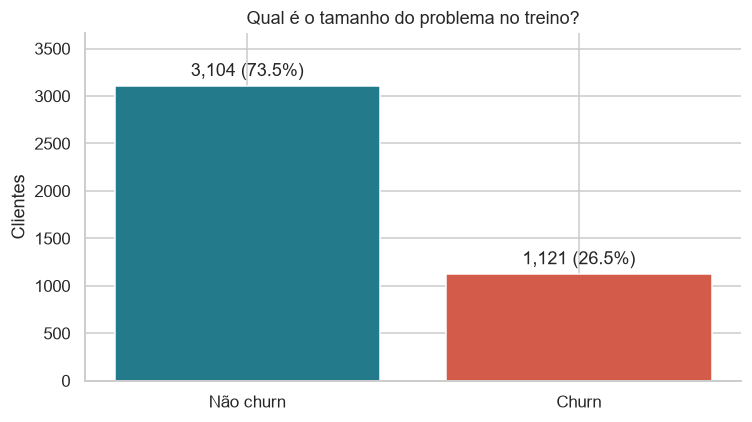

,count,mean,std,min,25%,50%,75%,max
tenure,"4,225.0000",32.2944,24.6679,0.0000,9.0000,29.0000,56.0000,72.0000
MonthlyCharges,"4,225.0000",64.7765,29.9892,18.4000,35.7500,70.4000,89.7500,118.7500
TotalCharges,"4,225.0000","2,284.0448","2,280.3337",0.0000,383.6500,"1,380.1000","3,825.8500","8,684.8000"


tenure                                        MonthlyCharges          \
       count    mean  median     std    min     max          count    mean   
Churn                                                                        
No      3104 37.5219 37.0000 24.2699 0.0000 72.0000           3104 61.2498   
Yes     1121 17.8198 10.0000 19.4314 1.0000 72.0000           1121 74.5415   

                                       TotalCharges                        \
       median     std     min      max        count       mean     median   
Churn                                                                       
No    64.3750 30.9597 18.4000 118.7500         3104 2,560.7925 1,672.1000   
Yes   79.7500 24.6244 18.8500 118.3500         1121 1,517.7425   679.3000   

                                     
             std     min        max  
Churn                                
No    2,349.6149  0.0000 8,672.4500  
Yes   1,875.0624 18.8500 8,684.8000

In [7]:
def wilson(sucessos, n, z=1.959963984540054):
    s, n = np.asarray(sucessos, dtype=float), np.asarray(n, dtype=float)
    p = s / n
    centro = (p + z*z/(2*n)) / (1 + z*z/n)
    meia = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centro-meia, centro+meia

def taxas_grupo(df, coluna):
    t = df.groupby(coluna, observed=True, dropna=False).churn.agg(n="size", churn="sum")
    t["taxa"] = t.churn / t.n
    t["ic95_inf"], t["ic95_sup"] = wilson(t.churn, t.n)
    return t.reset_index()

def barras_taxas(t, coluna, ax, titulo):
    pos = np.arange(len(t))
    ax.bar(pos, t.taxa, color="#237a8b")
    ax.errorbar(pos, t.taxa, yerr=np.vstack([t.taxa-t.ic95_inf, t.ic95_sup-t.taxa]),
                fmt="none", color="#283848", capsize=4)
    ax.set_xticks(pos, [f"{v}\n(n={n:,})" for v, n in zip(t[coluna].astype(str), t.n)],
                  rotation=15, ha="right")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(ylabel="Taxa de churn (IC 95%)", title=titulo,
           ylim=(0, min(1, float(t.ic95_sup.max())+0.13)))

contagem = eda.churn.value_counts().reindex([0,1])
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(["Não churn", "Churn"], contagem, color=["#237a8b", "#d35b4a"])
ax.bar_label(bars, labels=[f"{n:,} ({n/len(eda):.1%})" for n in contagem], padding=4)
ax.set(title="Qual é o tamanho do problema no treino?", ylabel="Clientes", ylim=(0, contagem.max()*1.18))
salvar_figura("01_distribuicao_churn")
display(eda[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T)
descritivas = eda.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(
    ["count", "mean", "median", "std", "min", "max"])
display(descritivas)
salvar_tabela(descritivas, "descritivas_por_churn", index=True)

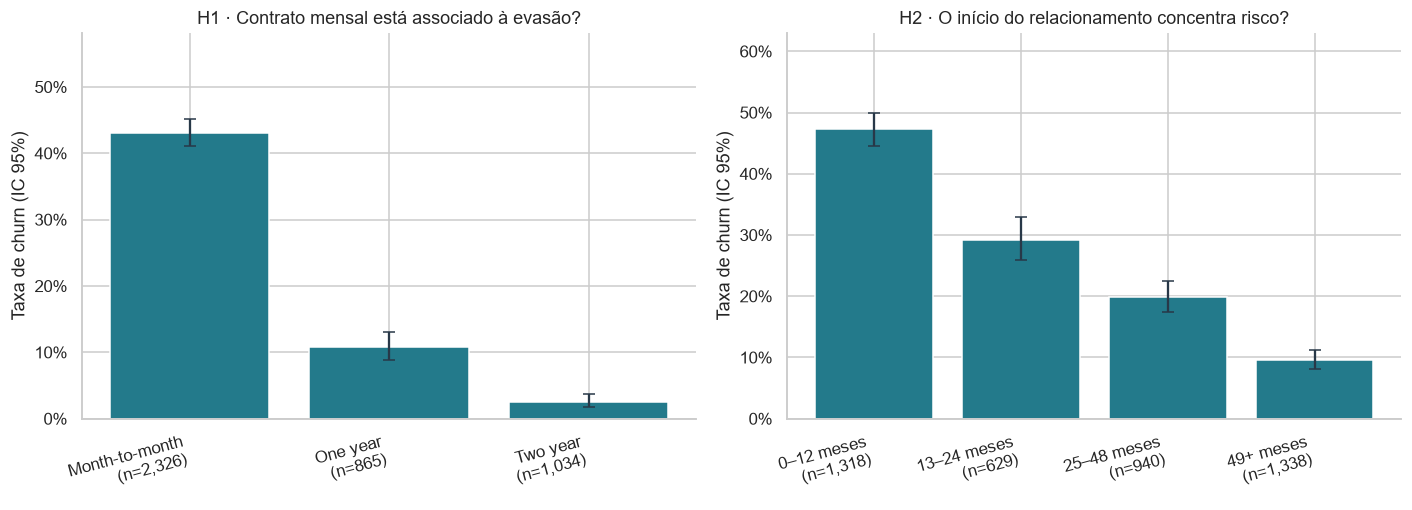

,Contract,n,churn,taxa,ic95_inf,ic95_sup
0,Month-to-month,2326,1002,0.4308,0.4108,0.4510
1,One year,865,93,0.1075,0.0886,0.1299
2,Two year,1034,26,0.0251,0.0172,0.0366


,FaixaPermanencia,n,churn,taxa,ic95_inf,ic95_sup
0,0–12 meses,1318,623,0.4727,0.4459,0.4997
1,13–24 meses,629,184,0.2925,0.2583,0.3293
2,25–48 meses,940,186,0.1979,0.1737,0.2245
3,49+ meses,1338,128,0.0957,0.0810,0.1126


In [8]:
eda["FaixaPermanencia"] = pd.cut(eda.tenure, [-1, 12, 24, 48, np.inf],
                                 labels=["0–12 meses", "13–24 meses", "25–48 meses", "49+ meses"])
contratos = taxas_grupo(eda, "Contract")
permanencia = taxas_grupo(eda, "FaixaPermanencia")
fig, axes = plt.subplots(1,2,figsize=(13,4.8))
barras_taxas(contratos, "Contract", axes[0], "H1 · Contrato mensal está associado à evasão?")
barras_taxas(permanencia, "FaixaPermanencia", axes[1], "H2 · O início do relacionamento concentra risco?")
salvar_figura("02_contrato_permanencia")
salvar_tabela(contratos, "taxas_contrato")
salvar_tabela(permanencia, "taxas_permanencia")
display(contratos)
display(permanencia)

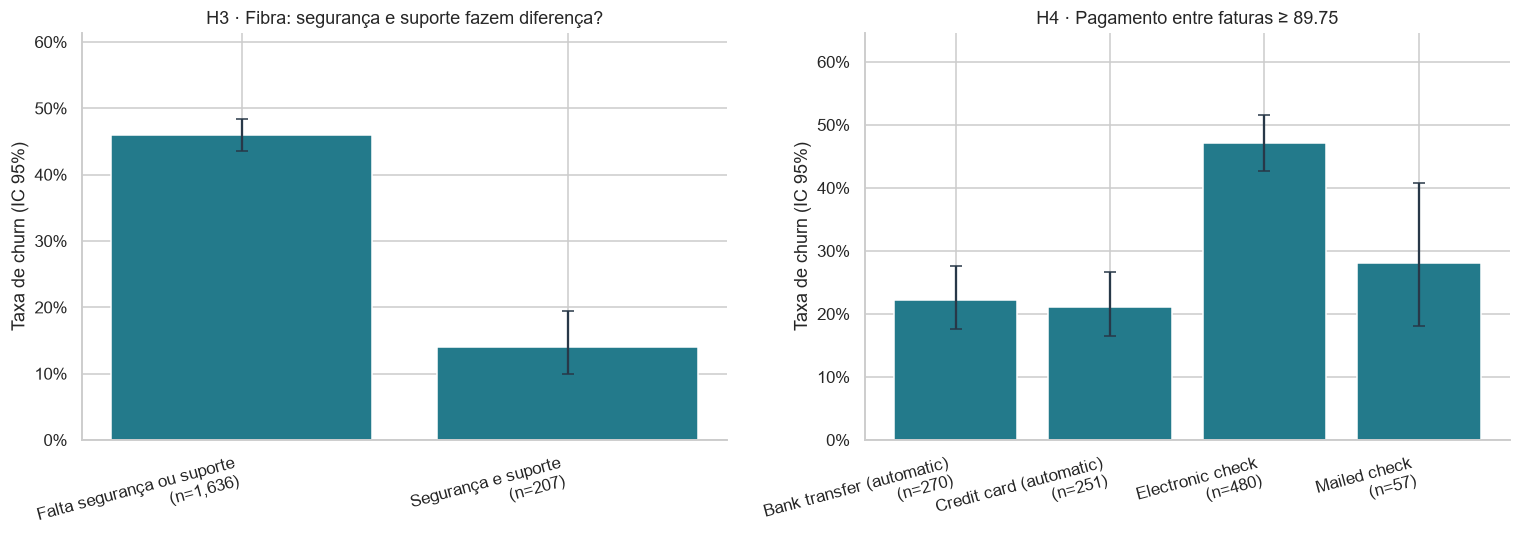

,PerfilSuporte,n,churn,taxa,ic95_inf,ic95_sup
0,Falta segurança ou suporte,1636,751,0.4590,0.4350,0.4833
1,Segurança e suporte,207,29,0.1401,0.0993,0.1940


,PaymentMethod,n,churn,taxa,ic95_inf,ic95_sup
0,Bank transfer (automatic),270,60,0.2222,0.1767,0.2755
1,Credit card (automatic),251,53,0.2112,0.1652,0.2658
2,Electronic check,480,226,0.4708,0.4266,0.5155
3,Mailed check,57,16,0.2807,0.1808,0.4083


In [9]:
fibra = eda.loc[eda.InternetService.eq("Fiber optic")].copy()
fibra["PerfilSuporte"] = np.where(fibra.OnlineSecurity.eq("Yes") & fibra.TechSupport.eq("Yes"),
                                  "Segurança e suporte", "Falta segurança ou suporte")
suporte = taxas_grupo(fibra, "PerfilSuporte")
q75_fatura = float(eda.MonthlyCharges.quantile(.75))
eda["FaturaAlta"] = eda.MonthlyCharges.ge(q75_fatura)
pagamentos = taxas_grupo(eda.loc[eda.FaturaAlta], "PaymentMethod")
fig, axes = plt.subplots(1,2,figsize=(14,5.2))
barras_taxas(suporte, "PerfilSuporte", axes[0], "H3 · Fibra: segurança e suporte fazem diferença?")
barras_taxas(pagamentos, "PaymentMethod", axes[1], f"H4 · Pagamento entre faturas ≥ {q75_fatura:.2f}")
salvar_figura("03_suporte_pagamento")
salvar_tabela(suporte, "taxas_suporte_fibra")
salvar_tabela(pagamentos, "taxas_pagamento_fatura_alta")
display(suporte)
display(pagamentos)

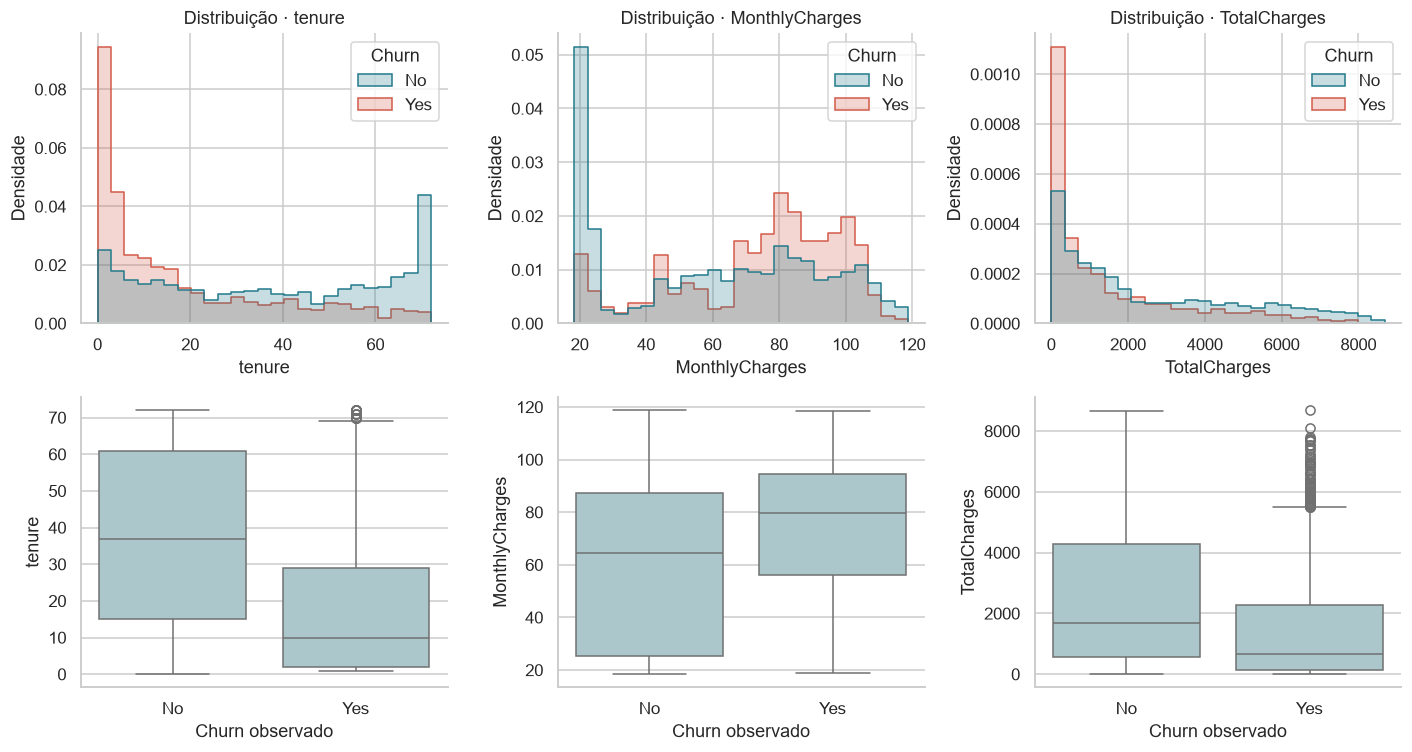

,variavel,limite_iqr_inf,limite_iqr_sup,fora_iqr,decisao
0,tenure,-61.5000,126.5000,0,Manter valores plausíveis; não excluir automat...
1,MonthlyCharges,-45.2500,170.7500,0,Manter valores plausíveis; não excluir automat...
2,TotalCharges,"-4,779.6500","8,989.1500",0,Manter valores plausíveis; não excluir automat...


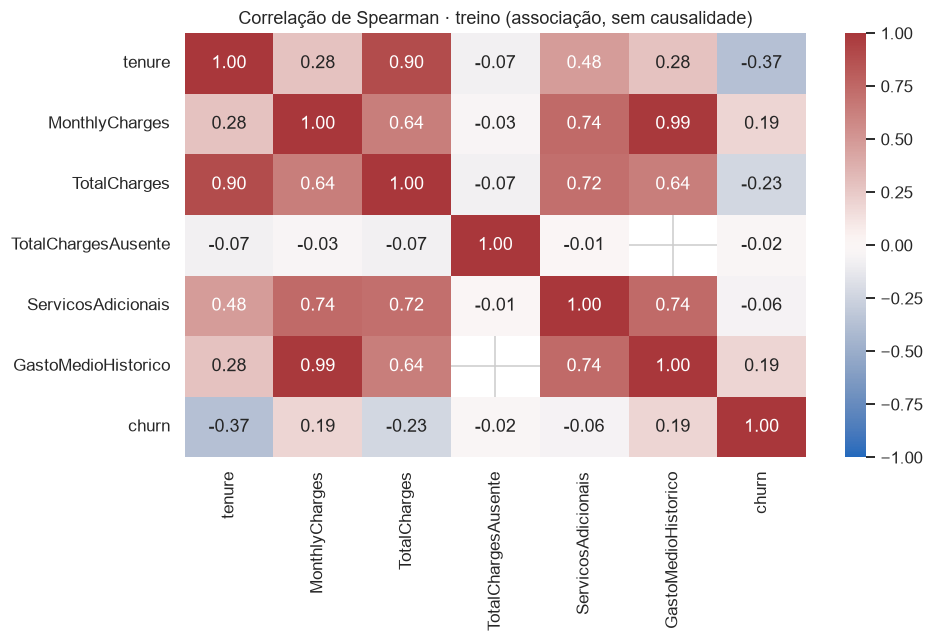

In [10]:
fig, axes = plt.subplots(2,3,figsize=(13,7))
for i,c in enumerate(["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=eda, x=c, hue="Churn", hue_order=["No", "Yes"], bins=25,
                 element="step", stat="density", common_norm=False, ax=axes[0,i])
    axes[0,i].set(title=f"Distribuição · {c}", ylabel="Densidade")
    sns.boxplot(data=eda, x="Churn", y=c, order=["No", "Yes"], color="#a6cbd0", ax=axes[1,i])
    axes[1,i].set_xlabel("Churn observado")
salvar_figura("04_distribuicoes_numericas")

extremos = []
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1,q3 = eda[c].quantile([.25,.75]); iqr=q3-q1
    baixo,alto = q1-1.5*iqr,q3+1.5*iqr
    extremos.append({"variavel":c,"limite_iqr_inf":baixo,"limite_iqr_sup":alto,
                     "fora_iqr":int(((eda[c]<baixo)|(eda[c]>alto)).sum()),
                     "decisao":"Manter valores plausíveis; não excluir automaticamente"})
display(pd.DataFrame(extremos))
salvar_tabela(pd.DataFrame(extremos), "auditoria_extremos")

corr = criar_atributos(raw.loc[idx_train])[NUMERICAS].assign(churn=y_train).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Spearman · treino (associação, sem causalidade)")
salvar_figura("05_correlacoes")
salvar_tabela(corr, "correlacoes_spearman", index=True)

## 5. Inferência: as quatro hipóteses da proposta

Os contrastes são definidos explicitamente antes de testar:

| Hipótese | Grupo exposto | Comparação |
|---|---|---|
| H1 | Contrato mensal | Contratos de um/dois anos |
| H2 | `tenure ≤ 12` | `tenure > 12` |
| H3 | Dentro da fibra, falta segurança **ou** suporte | Fibra com ambos contratados |
| H4 | Fatura ≥ P75 do treino e cheque eletrônico | Fatura ≥ P75 e débito/cartão automático |

H2 testa a associação com permanência curta; não estima risco longitudinal nem
prova queda progressiva. H3 não compara clientes sem internet com assinantes de fibra.
H4 exclui cheque pelo correio e compara dentro da faixa alta; não isola efeito causal
de preço/pagamento e não testa formalmente uma interação.

H0 é igualdade de proporções em cada contraste. Usamos qui-quadrado de Pearson
bilateral, ou Fisher se houver frequência esperada < 5. Corrigimos os quatro
p-valores por **Holm** (α=0,05). Reportamos taxas com IC Wilson, diferença em pontos
percentuais, razão de riscos (RR) com IC log aproximado e V de Cramér.
O IC de RR é individual, sem ajuste por multiplicidade; significância usa Holm.
Rejeitar H0 com taxa no sentido previsto sustenta associação, não causa.

In [11]:
def comparar_hipotese(nome, dados, exposto, comparacao):
    a = dados.loc[exposto, "churn"].to_numpy()
    b = dados.loc[comparacao, "churn"].to_numpy()
    if len(a)==0 or len(b)==0:
        raise ValueError(f"{nome}: contraste sem observações em um dos grupos.")
    tabela = np.array([[a.sum(), len(a)-a.sum()], [b.sum(), len(b)-b.sum()]], dtype=float)
    chi2,p,_,esperados = chi2_contingency(tabela, correction=False)
    teste="Qui-quadrado de Pearson"
    if (esperados<5).any():
        _,p=fisher_exact(tabela.astype(int), alternative="two-sided")
        teste="Fisher bilateral"
    # Correção de Haldane-Anscombe só para RR/IC caso alguma célula seja zero.
    ajustada=tabela + (0.5 if (tabela==0).any() else 0)
    a1,a0=ajustada[0]; b1,b0=ajustada[1]
    rr=(a1/(a1+a0))/(b1/(b1+b0))
    se=np.sqrt(1/a1-1/(a1+a0)+1/b1-1/(b1+b0))
    ai,asup=wilson(a.sum(),len(a)); bi,bsup=wilson(b.sum(),len(b))
    return {"hipotese":nome,"n_exposto":len(a),"n_comparacao":len(b),
        "churn_exposto":int(a.sum()),"churn_comparacao":int(b.sum()),
        "taxa_exposto":a.mean(),"taxa_comparacao":b.mean(),
        "ic_exposto_inf":float(ai),"ic_exposto_sup":float(asup),
        "ic_comparacao_inf":float(bi),"ic_comparacao_sup":float(bsup),
        "diferenca_pp":100*(a.mean()-b.mean()),"risco_relativo":rr,
        "rr_ic95_inf":np.exp(np.log(rr)-1.96*se),"rr_ic95_sup":np.exp(np.log(rr)+1.96*se),
        "v_cramer":np.sqrt(chi2/tabela.sum()),"p_valor":p,"teste":teste}

automatico=eda.PaymentMethod.isin(["Bank transfer (automatic)", "Credit card (automatic)"])
ambos=fibra.OnlineSecurity.eq("Yes") & fibra.TechSupport.eq("Yes")
hipoteses=pd.DataFrame([
    comparar_hipotese("H1",eda,eda.Contract.eq("Month-to-month"),~eda.Contract.eq("Month-to-month")),
    comparar_hipotese("H2",eda,eda.tenure.le(12),eda.tenure.gt(12)),
    comparar_hipotese("H3",fibra,~ambos,ambos),
    comparar_hipotese("H4",eda,eda.FaturaAlta & eda.PaymentMethod.eq("Electronic check"),
                      eda.FaturaAlta & automatico),
])
ordem=np.argsort(hipoteses.p_valor.to_numpy())
p_ord=hipoteses.p_valor.to_numpy()[ordem]
p_holm=np.empty(len(p_ord))
p_holm[ordem]=np.minimum(1,np.maximum.accumulate(p_ord*np.arange(len(p_ord),0,-1)))
hipoteses["p_holm"]=p_holm
hipoteses["associacao_sentido_previsto"]=(hipoteses.p_holm<.05)&(hipoteses.diferenca_pp>0)
display(hipoteses)
salvar_tabela(hipoteses,"testes_hipoteses")
for r in hipoteses.itertuples():
    decisao="Evidência no sentido previsto" if r.associacao_sentido_previsto else "Sem suporte suficiente no sentido previsto"
    display(Markdown(f"**{r.hipotese}: {decisao}.** Taxas {r.taxa_exposto:.1%} vs "
        f"{r.taxa_comparacao:.1%}; diferença {r.diferenca_pp:.1f} p.p.; "
        f"RR={r.risco_relativo:.2f} (IC95% {r.rr_ic95_inf:.2f}–{r.rr_ic95_sup:.2f}); "
        f"p ajustado={r.p_holm:.3g}."))

,hipotese,n_exposto,n_comparacao,churn_exposto,churn_comparacao,taxa_exposto,taxa_comparacao,ic_exposto_inf,ic_exposto_sup,ic_comparacao_inf,ic_comparacao_sup,diferenca_pp,risco_relativo,rr_ic95_inf,rr_ic95_sup,v_cramer,p_valor,teste,p_holm,associacao_sentido_previsto
0,H1,2326,1899,1002,119,0.4308,0.0627,0.4108,0.4510,0.0526,0.0745,36.8118,6.8744,5.7413,8.2311,0.4148,0.0000,Qui-quadrado de Pearson,0.0000,True
1,H2,1318,2907,623,498,0.4727,0.1713,0.4459,0.4997,0.1580,0.1854,30.1375,2.7592,2.5011,3.0440,0.3162,0.0000,Qui-quadrado de Pearson,0.0000,True
2,H3,1636,207,751,29,0.4590,0.1401,0.4350,0.4833,0.0993,0.1940,31.8950,3.2766,2.3285,4.6108,0.2038,0.0000,Qui-quadrado de Pearson,0.0000,True
3,H4,480,521,226,113,0.4708,0.2169,0.4266,0.5155,0.1836,0.2543,25.3943,2.1708,1.7975,2.6217,0.2681,0.0000,Qui-quadrado de Pearson,0.0000,True


**H1: Evidência no sentido previsto.** Taxas 43.1% vs 6.3%; diferença 36.8 p.p.; RR=6.87 (IC95% 5.74–8.23); p ajustado=1.79e-159.

**H2: Evidência no sentido previsto.** Taxas 47.3% vs 17.1%; diferença 30.1 p.p.; RR=2.76 (IC95% 2.50–3.04); p ajustado=2.04e-93.

**H3: Evidência no sentido previsto.** Taxas 45.9% vs 14.0%; diferença 31.9 p.p.; RR=3.28 (IC95% 2.33–4.61); p ajustado=4.24e-18.

**H4: Evidência no sentido previsto.** Taxas 47.1% vs 21.7%; diferença 25.4 p.p.; RR=2.17 (IC95% 1.80–2.62); p ajustado=2.23e-17.

**Análise complementar exploratória:** Mann-Whitney U compara a distribuição de
permanência entre churn/não churn, com efeito rank-biserial. Esse teste não é
uma quinta hipótese confirmatória e seu p-valor não integra a família H1–H4.
O teste não é, em geral, um teste de igualdade de médias ou medianas.

In [12]:
a=eda.loc[eda.churn.eq(1),"tenure"]
b=eda.loc[eda.churn.eq(0),"tenure"]
u,p_mw=mannwhitneyu(a,b,alternative="two-sided",method="asymptotic")
mw=pd.DataFrame([{"analise":"Exploratória: tenure por churn", "n_churn":len(a),
    "n_nao_churn":len(b),"mediana_churn":a.median(),"mediana_nao_churn":b.median(),
    "U":u,"p_nao_ajustado":p_mw,"efeito_rank_biserial":2*u/(len(a)*len(b))-1}])
display(mw)
salvar_tabela(mw,"mann_whitney_exploratorio")

,analise,n_churn,n_nao_churn,mediana_churn,mediana_nao_churn,U,p_nao_ajustado,efeito_rank_biserial
0,Exploratória: tenure por churn,1121,3104,10.0000,37.0000,"902,945.5000",0.0000,-0.4810


## 6. Métodos e métricas

| Método | Justificativa |
|---|---|
| Dummy por prevalência | Referência sem informação: impede interpretar acurácia majoritária como sucesso |
| Regressão Logística | Baseline interpretável, regularização L2 e pesos opcionais |
| Árvore de Decisão | Interações simples, profundidade controlada; árvores representam relações não lineares |
| Random Forest | Ensemble para interações e menor variância, com tamanho mínimo de folhas |
| HistGradientBoosting | Boosting não linear, regularizado, disponível no scikit-learn |

O boosting nativo evita a instalação adicional de XGBoost/LightGBM, citados como
possibilidades na proposta (os métodos iniciais não eram compromisso de entrega).
Usamos one-hot também para o boosting por consistência com os demais modelos.
Pesos de classe são candidatos da busca; não fazemos reamostragem antes da divisão.

**Métrica primária de seleção: AP**, resumo da curva precisão-revocação calculado
como average precision, sensível à classe positiva. AP não é área trapezoidal PR.
Também reportamos ROC-AUC, precisão, revocação, F1, F2, acurácia, acurácia balanceada
e Brier. Acurácia isolada pode favorecer a classe majoritária. As métricas de classe
dependem do limiar; ROC-AUC/AP dependem do ranqueamento; Brier avalia probabilidades.

Dummy: AP em CV=0.2653


Regressão Logística: AP em CV=0.6668


Árvore de Decisão: AP em CV=0.6029


Random Forest: AP em CV=0.6717


HistGradientBoosting: AP em CV=0.6620


,modelo,AP_cv,AP_dp_folds,ROC_AUC_cv,F1_cv_limiar_05,AP_treino,parametros
0,Random Forest,0.6717,0.0115,0.8485,0.5721,0.7886,"{'modelo__class_weight': None, 'modelo__max_de..."
1,Regressão Logística,0.6668,0.0246,0.8482,0.5977,0.6754,"{'modelo__C': 1.0, 'modelo__class_weight': None}"
2,HistGradientBoosting,0.6620,0.0158,0.8419,0.5821,0.7860,"{'modelo__class_weight': None, 'modelo__l2_reg..."
3,Árvore de Decisão,0.6029,0.0213,0.8168,0.5514,0.6975,"{'modelo__class_weight': None, 'modelo__max_de..."
4,Dummy,0.2653,0.0005,0.5000,0.0000,0.2653,{}


Selecionado por AP no treino: Random Forest. Tempo: 99.0s


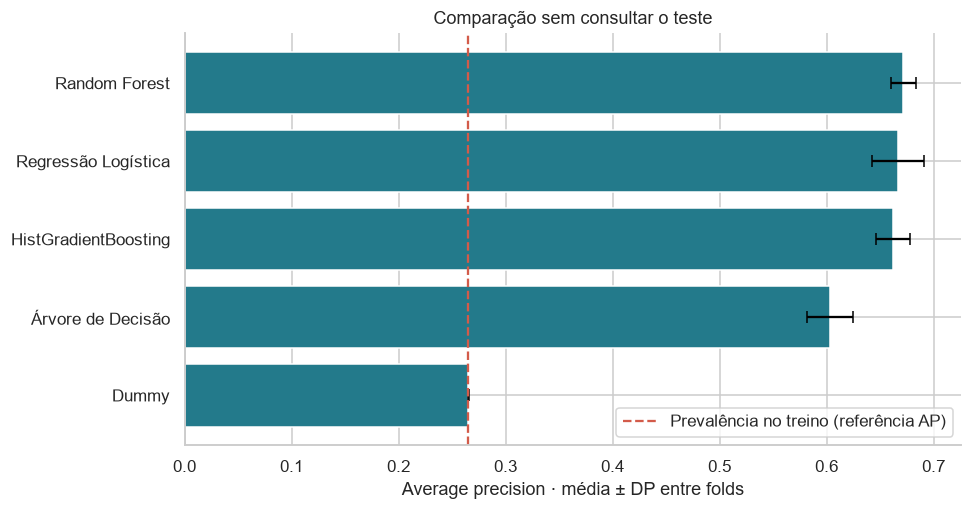

In [13]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
candidatos={
    "Dummy":(DummyClassifier(strategy="prior"),{}),
    "Regressão Logística":(LogisticRegression(max_iter=2000,random_state=SEED),
        {"modelo__C":[.1,1.0],"modelo__class_weight":[None,"balanced"]}),
    "Árvore de Decisão":(DecisionTreeClassifier(random_state=SEED),
        {"modelo__max_depth":[3,6],"modelo__min_samples_leaf":[25],
         "modelo__class_weight":[None,"balanced"]}),
    "Random Forest":(RandomForestClassifier(n_estimators=180,random_state=SEED,n_jobs=N_JOBS),
        {"modelo__max_depth":[8,None],"modelo__min_samples_leaf":[5],
         "modelo__class_weight":[None,"balanced_subsample"]}),
    "HistGradientBoosting":(HistGradientBoostingClassifier(max_iter=160,early_stopping=False,
                                                        random_state=SEED),
        {"modelo__max_leaf_nodes":[7,15],"modelo__l2_regularization":[1.0],
         "modelo__class_weight":[None,"balanced"]}),
}
buscas={}; linhas_cv=[]; detalhes_cv=[]
inicio=time.perf_counter()
for nome,(estimador,grade) in candidatos.items():
    busca=GridSearchCV(montar_pipeline(estimador),grade,
        scoring={"ap":"average_precision","roc_auc":"roc_auc","f1":"f1"},
        refit="ap",cv=cv,n_jobs=N_JOBS,error_score="raise",return_train_score=True)
    with threadpool_limits(limits=2):
        busca.fit(X_train,y_train)
    buscas[nome]=busca
    r=busca.cv_results_; i=busca.best_index_
    linhas_cv.append({"modelo":nome,"AP_cv":r["mean_test_ap"][i],
        "AP_dp_folds":r["std_test_ap"][i],"ROC_AUC_cv":r["mean_test_roc_auc"][i],
        "F1_cv_limiar_05":r["mean_test_f1"][i],"AP_treino":r["mean_train_ap"][i],
        "parametros":str(busca.best_params_)})
    detalhe=pd.DataFrame(r);detalhe.insert(0,"modelo",nome);detalhes_cv.append(detalhe)
    print(f"{nome}: AP em CV={busca.best_score_:.4f}",flush=True)
comparacao=pd.DataFrame(linhas_cv).sort_values("AP_cv",ascending=False).reset_index(drop=True)
nome_vencedor=comparacao.iloc[0].modelo
selecionado=buscas[nome_vencedor].best_estimator_
display(comparacao)
print(f"Selecionado por AP no treino: {nome_vencedor}. Tempo: {time.perf_counter()-inicio:.1f}s")
salvar_tabela(comparacao,"comparacao_modelos_cv")
salvar_tabela(pd.concat(detalhes_cv,ignore_index=True),"busca_completa_cv")
fig,ax=plt.subplots(figsize=(9,4.8))
ax.barh(comparacao.modelo[::-1],comparacao.AP_cv[::-1],xerr=comparacao.AP_dp_folds[::-1],color="#237a8b",capsize=4)
ax.axvline(y_train.mean(),ls="--",color="#d35b4a",label="Prevalência no treino (referência AP)")
ax.set(xlabel="Average precision · média ± DP entre folds",title="Comparação sem consultar o teste")
ax.legend(loc="lower right")
salvar_figura("06_comparacao_cv")

As médias de CV acima são utilizadas para seleção; o melhor resultado pode ter
otimismo de seleção e o desvio entre folds não é um intervalo de confiança.
O teste independente é a estimativa final. O F1 de CV usa 0,5, sem otimização
de limiar por modelo. Não escolheremos outro método após consultar o teste.

## 7. Calibração e limiar — sem consultar o teste

Pesos de classe podem alterar a escala das probabilidades. Aplicamos calibração
sigmoid em CV dentro do treino, sem usar validação/teste no ajuste. O ensemble
calibrado mantém três modelos, cada um com seu pré-processamento ajustado no fold.
Na validação, escolhemos o limiar que maximiza F2; empates favorecem o maior limiar
(menos contatos). A qualidade de calibração ainda deve ser verificada; não se
presume que a saída corresponda a probabilidades futuras de produção.

Limiar congelado: 0.1003 | F2 na validação: 0.7379
Brier validação: bruto=0.1380; calibrado=0.1376


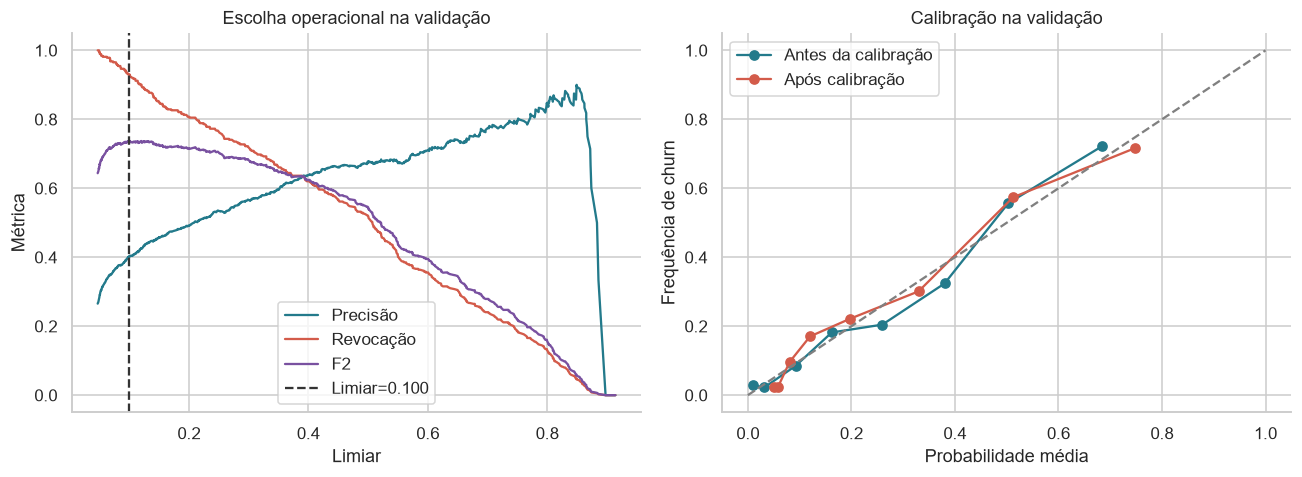

In [14]:
cv_cal=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+1)
modelo=CalibratedClassifierCV(estimator=clone(selecionado),method="sigmoid",cv=cv_cal,
                             ensemble=True,n_jobs=N_JOBS)
with threadpool_limits(limits=2):
    modelo.fit(X_train,y_train)
p_val=modelo.predict_proba(X_val)[:,1]
p_val_bruto=selecionado.predict_proba(X_val)[:,1]
prec,rec,limiares=precision_recall_curve(y_val,p_val)
f2=5*prec[:-1]*rec[:-1]/np.maximum(4*prec[:-1]+rec[:-1],1e-15)
melhores=np.flatnonzero(np.isclose(f2,f2.max(),rtol=0,atol=1e-12))
idx_limiar=int(melhores[-1])
LIMIAR=float(limiares[idx_limiar])
curva_limiar=pd.DataFrame({"limiar":limiares,"precisao":prec[:-1],"revocacao":rec[:-1],"F2":f2})
salvar_tabela(curva_limiar,"limiar_validacao")
print(f"Limiar congelado: {LIMIAR:.4f} | F2 na validação: {f2[idx_limiar]:.4f}")
print(f"Brier validação: bruto={brier_score_loss(y_val,p_val_bruto):.4f}; calibrado={brier_score_loss(y_val,p_val):.4f}")
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for c,cor,rotulo in [("precisao","#237a8b","Precisão"),
                     ("revocacao","#d35b4a","Revocação"),("F2","#7951a0","F2")]:
    axes[0].plot(curva_limiar.limiar,curva_limiar[c],color=cor,label=rotulo)
axes[0].axvline(LIMIAR,color="#333333",ls="--",label=f"Limiar={LIMIAR:.3f}")
axes[0].set(xlabel="Limiar",ylabel="Métrica",title="Escolha operacional na validação");axes[0].legend()
for probs,label in [(p_val_bruto,"Antes da calibração"),(p_val,"Após calibração")]:
    observado,previsto=calibration_curve(y_val,probs,n_bins=8,strategy="quantile")
    axes[1].plot(previsto,observado,"o-",label=label)
axes[1].plot([0,1],[0,1],"--",color="gray")
axes[1].set(xlabel="Probabilidade média",ylabel="Frequência de churn",title="Calibração na validação");axes[1].legend()
salvar_figura("07_limiar_calibracao_validacao")

## 8. Avaliação final no teste reservado

Modelo, hiperparâmetros, calibração e limiar agora estão congelados. O modelo
permanece ajustado somente nos 60% de treino: reajustá-lo com a validação mudaria
a escala usada para escolher o limiar. Avaliamos apenas essa solução e o Dummy
de referência; a comparação entre os demais métodos está na CV.
O limiar 0,5 aparece como referência para mostrar o custo de priorizar revocação.

,solucao,limiar,ROC_AUC,AP,precisao,revocacao,F1,F2,acuracia,acuracia_balanceada,Brier,fracao_contatada
0,"Dummy (0,5)",0.5000,0.5000,0.2654,0.0000,0.0000,0.0000,0.0000,0.7346,0.5000,0.1950,0.0000
1,"Random Forest calibrado (0,5)",0.5000,0.8428,0.6537,0.6479,0.4920,0.5593,0.5169,0.7942,0.6977,0.1373,0.2016
2,Random Forest calibrado (F2),0.1003,0.8428,0.6537,0.4172,0.9358,0.5771,0.7495,0.6359,0.7317,0.1373,0.5955


              precision    recall  f1-score   support

   Não churn       0.96      0.53      0.68      1035
       Churn       0.42      0.94      0.58       374

    accuracy                           0.64      1409
   macro avg       0.69      0.73      0.63      1409
weighted avg       0.81      0.64      0.65      1409



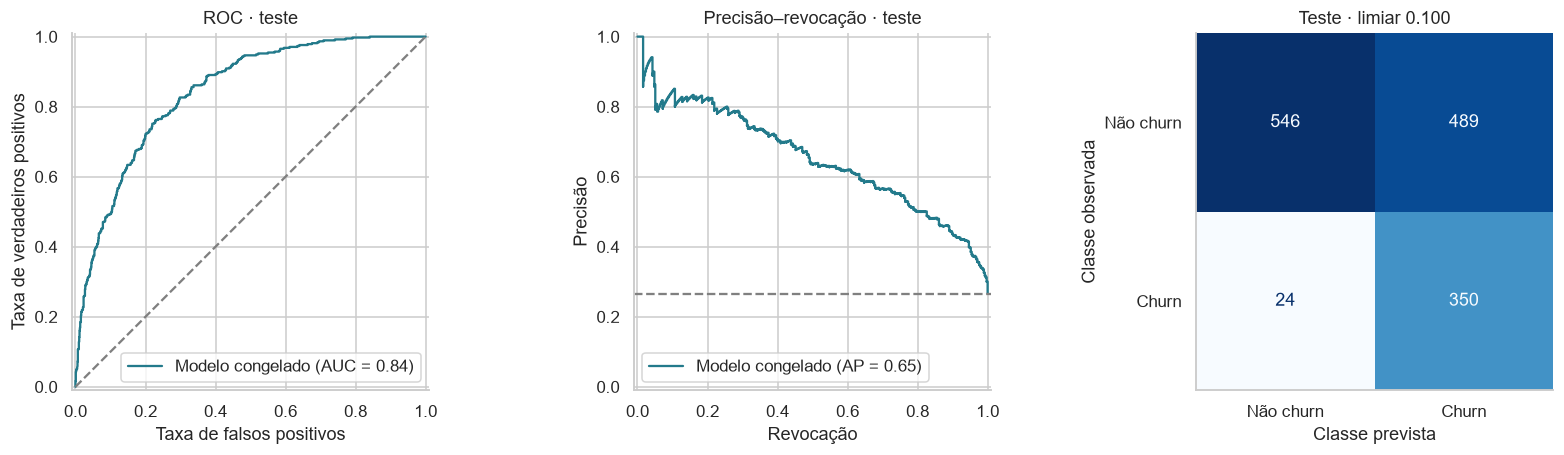

In [15]:
from sklearn.metrics import balanced_accuracy_score

def metricas(y_real,prob,limiar):
    pred=(np.asarray(prob)>=limiar).astype(int)
    return {"ROC_AUC":roc_auc_score(y_real,prob),"AP":average_precision_score(y_real,prob),
        "precisao":precision_score(y_real,pred,zero_division=0),
        "revocacao":recall_score(y_real,pred,zero_division=0),
        "F1":f1_score(y_real,pred,zero_division=0),
        "F2":fbeta_score(y_real,pred,beta=2,zero_division=0),
        "acuracia":accuracy_score(y_real,pred),
        "acuracia_balanceada":balanced_accuracy_score(y_real,pred),
        "Brier":brier_score_loss(y_real,prob),"fracao_contatada":pred.mean()}

p_test=modelo.predict_proba(X_test)[:,1]
pred_test=(p_test>=LIMIAR).astype(int)
p_dummy=buscas["Dummy"].best_estimator_.predict_proba(X_test)[:,1]
resultados=pd.DataFrame([
    {"solucao":"Dummy (0,5)","limiar":.5,**metricas(y_test,p_dummy,.5)},
    {"solucao":f"{nome_vencedor} calibrado (0,5)","limiar":.5,**metricas(y_test,p_test,.5)},
    {"solucao":f"{nome_vencedor} calibrado (F2)","limiar":LIMIAR,**metricas(y_test,p_test,LIMIAR)},
])
display(resultados)
salvar_tabela(resultados,"metricas_teste")
print(classification_report(y_test,pred_test,target_names=["Não churn","Churn"],zero_division=0))
relatorio_classificacao=pd.DataFrame(classification_report(y_test,pred_test,
    target_names=["Não churn","Churn"],output_dict=True,zero_division=0)).T
salvar_tabela(relatorio_classificacao,"relatorio_classificacao",index=True)
cm=confusion_matrix(y_test,pred_test,labels=[0,1])
salvar_tabela(pd.DataFrame(cm,index=["real_0","real_1"],columns=["previsto_0","previsto_1"]),
              "matriz_confusao",index=True)
fig,axes=plt.subplots(1,3,figsize=(15,4.3))
RocCurveDisplay.from_predictions(y_test,p_test,ax=axes[0],name="Modelo congelado")
axes[0].plot([0,1],[0,1],"--",color="gray")
axes[0].set(title="ROC · teste",xlabel="Taxa de falsos positivos",ylabel="Taxa de verdadeiros positivos")
PrecisionRecallDisplay.from_predictions(y_test,p_test,ax=axes[1],name="Modelo congelado")
axes[1].axhline(y_test.mean(),ls="--",color="gray")
axes[1].set(title="Precisão–revocação · teste",xlabel="Revocação",ylabel="Precisão")
ConfusionMatrixDisplay(cm,display_labels=["Não churn","Churn"]).plot(ax=axes[2],colorbar=False,cmap="Blues")
axes[2].set(title=f"Teste · limiar {LIMIAR:.3f}",xlabel="Classe prevista",ylabel="Classe observada")
axes[2].grid(False)
salvar_figura("08_avaliacao_teste")

### Incerteza da avaliação

Bootstrap estratificado de 500 reamostragens dos pares (rótulo, previsão) do teste,
sem retreinar ou mudar limiar. ICs percentis de 95%, condicionais ao modelo e à
composição de classes observada; não incluem incerteza de seleção, treinamento,
prevalência futura ou mudança de distribuição. Não são usados para otimizar decisões.

In [16]:
rng=np.random.default_rng(SEED)
yt=y_test.to_numpy(); grupos=[np.flatnonzero(yt==k) for k in [0,1]]
amostras=[]
for _ in range(N_BOOTSTRAP):
    ix=np.concatenate([rng.choice(g,size=len(g),replace=True) for g in grupos])
    amostras.append(metricas(yt[ix],p_test[ix],LIMIAR))
boot=pd.DataFrame(amostras)
ic=pd.DataFrame({"estimativa":pd.Series(metricas(y_test,p_test,LIMIAR)),
                  "ic95_inf":boot.quantile(.025),"ic95_sup":boot.quantile(.975)})
display(ic)
salvar_tabela(ic,"ic_bootstrap_teste",index=True)

,estimativa,ic95_inf,ic95_sup
ROC_AUC,0.8428,0.8226,0.8639
AP,0.6537,0.6125,0.6985
precisao,0.4172,0.3995,0.4347
revocacao,0.9358,0.9091,0.9613
F1,0.5771,0.5585,0.5963
F2,0.7495,0.7296,0.7697
acuracia,0.6359,0.6114,0.6593
acuracia_balanceada,0.7317,0.7113,0.7518
Brier,0.1373,0.1281,0.1466
fracao_contatada,0.5955,0.5731,0.6200


## 9. Capacidade de contato e interpretação

Uma equipe com limite de contatos precisa de um ranking, além do limiar F2.
As capacidades de 10%, 20%, 30% e 50% são cenários definidos para avaliação,
não percentuais escolhidos para maximizar resultados no teste. `Lift@k` compara
precisão no topo com a prevalência do teste; captura mede a fração de churns
observados alcançados. A fração de contato usa `ceil(k*n)`, exposta na tabela.

,capacidade_planejada,contatos,fracao_real,churns_alcancados,precisao_top,captura,lift
0,0.1000,141,0.1001,109,0.7730,0.2914,2.9124
1,0.2000,282,0.2001,184,0.6525,0.4920,2.4581
2,0.3000,423,0.3002,248,0.5863,0.6631,2.2088
3,0.5000,705,0.5004,324,0.4596,0.8663,1.7314


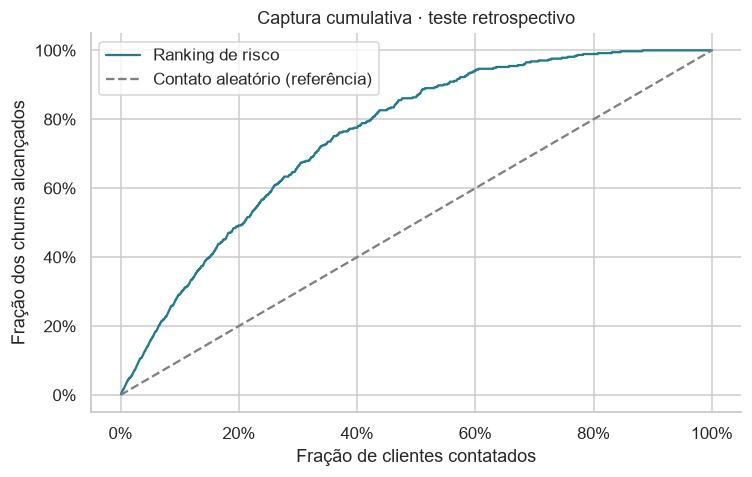

In [17]:
ranking=pd.DataFrame({"customerID":raw.loc[idx_test,"customerID"].to_numpy(),
    "churn_real":y_test.to_numpy(),"probabilidade":p_test,
    "MonthlyCharges":raw.loc[idx_test,"MonthlyCharges"].to_numpy()})
ranking=ranking.sort_values(["probabilidade","customerID"],ascending=[False,True]).reset_index(drop=True)
ranking["decisao_limiar"]=(ranking.probabilidade>=LIMIAR).astype(int)
ranking["posicao"]=np.arange(1,len(ranking)+1)
ranking["captura_acumulada"]=ranking.churn_real.cumsum()/ranking.churn_real.sum()
linhas_cap=[]
for capacidade in [.1,.2,.3,.5]:
    n=int(np.ceil(capacidade*len(ranking)));top=ranking.head(n)
    linhas_cap.append({"capacidade_planejada":capacidade,"contatos":n,"fracao_real":n/len(ranking),
        "churns_alcancados":int(top.churn_real.sum()),"precisao_top":top.churn_real.mean(),
        "captura":top.churn_real.sum()/ranking.churn_real.sum(),
        "lift":top.churn_real.mean()/ranking.churn_real.mean()})
capacidade_tabela=pd.DataFrame(linhas_cap)
display(capacidade_tabela)
salvar_tabela(capacidade_tabela,"capacidade_contato_teste")
salvar_tabela(ranking,"ranking_teste_retrospectivo")
fig,ax=plt.subplots(figsize=(7,4.5))
ax.plot(ranking.posicao/len(ranking),ranking.captura_acumulada,label="Ranking de risco")
ax.plot([0,1],[0,1],"--",color="gray",label="Contato aleatório (referência)")
ax.set(xlabel="Fração de clientes contatados",ylabel="Fração dos churns alcançados",
       title="Captura cumulativa · teste retrospectivo")
ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend()
salvar_figura("09_captura_contatos")

### Quais variáveis sustentam o ranking?

Importância por permutação nas **colunas originais da validação**, medida como
queda de AP ao embaralhar uma variável. O pipeline recalcula os atributos derivados.
Isso evita interpretar apenas a importância interna de árvores, mas correlações
podem repartir ou mascarar importância. Média ± desvio de 8 permutações não é
IC estatístico. Importância não indica sinal nem efeito causal.

Permutar livremente serviços criaria cadastros impossíveis (ex.: sem internet com
suporte contratado). Por isso a interpretação abaixo permuta **blocos coerentes**:
telefonia/linhas e internet/seis serviços são movidos juntos. As outras colunas são
permutadas individualmente. O ranking não entra na seleção do modelo.

,bloco,colunas,queda_AP_media,queda_AP_dp
1,Internet + serviços,"InternetService, OnlineSecurity, OnlineBackup,...",0.1271,0.0249
9,tenure,tenure,0.0687,0.0158
6,Contract,Contract,0.0656,0.0130
11,TotalCharges,TotalCharges,0.0092,0.0076
10,MonthlyCharges,MonthlyCharges,0.0061,0.0074
7,PaperlessBilling,PaperlessBilling,0.0059,0.0038
0,Telefonia + linhas,"PhoneService, MultipleLines",0.0044,0.0036
8,PaymentMethod,PaymentMethod,0.0021,0.0026
3,SeniorCitizen,SeniorCitizen,0.0008,0.0013
4,Partner,Partner,0.0001,0.0017


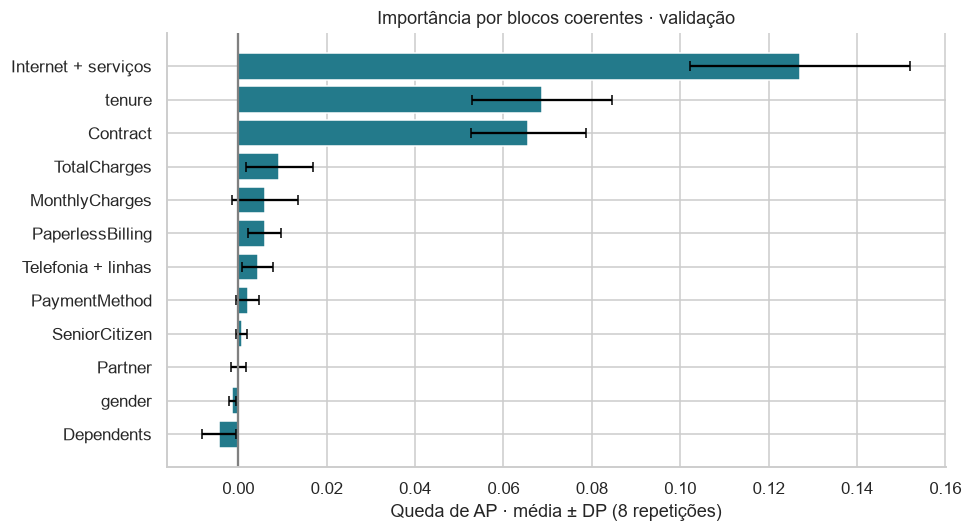

In [18]:
from telco_pipeline import SERVICOS
blocos={"Telefonia + linhas":["PhoneService","MultipleLines"],
        "Internet + serviços":["InternetService"]+SERVICOS}
usadas=set(sum(blocos.values(),[]))
blocos.update({c:[c] for c in PREDITORES if c not in usadas})
base_ap=average_precision_score(y_val,p_val)
rng_perm=np.random.default_rng(SEED)
linhas_imp=[]
with threadpool_limits(limits=2):
    for nome,colunas in blocos.items():
        quedas=[]
        for _ in range(8):
            perm=rng_perm.permutation(len(X_val));xp=X_val.copy()
            xp.loc[:,colunas]=X_val.iloc[perm][colunas].to_numpy()
            pp=modelo.predict_proba(xp)[:,1]
            quedas.append(base_ap-average_precision_score(y_val,pp))
        linhas_imp.append({"bloco":nome,"colunas":", ".join(colunas),
                           "queda_AP_media":np.mean(quedas),"queda_AP_dp":np.std(quedas)})
importancias=pd.DataFrame(linhas_imp).sort_values("queda_AP_media",ascending=False)
display(importancias)
salvar_tabela(importancias,"importancia_permutacao_validacao")
top=importancias.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(top.bloco,top.queda_AP_media,xerr=top.queda_AP_dp,color="#237a8b",capsize=3)
ax.axvline(0,color="gray");ax.set(xlabel="Queda de AP · média ± DP (8 repetições)",
    title="Importância por blocos coerentes · validação")
salvar_figura("10_importancia_permutacao")

## 10. Simulação financeira e recomendações acionáveis

**Simulação, não resultado de campanha.** Suponha contato nos 20% de maior risco
(capacidade pré-fixada), custo de 10 unidades por contato, horizonte de 3 meses,
margem de contribuição de 40% da fatura e eficácia de retenção de 10%, 20% ou 30%
entre clientes que cancelariam. Essas premissas são hipotéticas e editáveis.

Usamos os rótulos retrospectivos para ilustrar a conta:
`benefício = eficácia × soma(faturas dos churns alcançados) × meses × margem`;
`resultado incremental simulado = benefício − custo de todos os contatos`.
Não há desconto, custo adicional de oferta, valor do dinheiro no tempo ou efeito
sobre outros clientes nesta simplificação. Não é CLV. A eficácia é desconhecida
e deve ser medida em experimento com grupo controle; o modelo de risco não estima
quem responderá à ação (uplift). Valores em unidades da base, sem conversão de moeda.

,eficacia_hipotetica,contatos,custo,beneficio_simulado,resultado_simulado,ROI_simulado,eficacia_equilibrio
0,0.1000,282,"2,820.0000","1,709.1540","-1,110.8460",-0.3939,0.1650
1,0.2000,282,"2,820.0000","3,418.3080",598.3080,0.2122,0.1650
2,0.3000,282,"2,820.0000","5,127.4620","2,307.4620",0.8182,0.1650


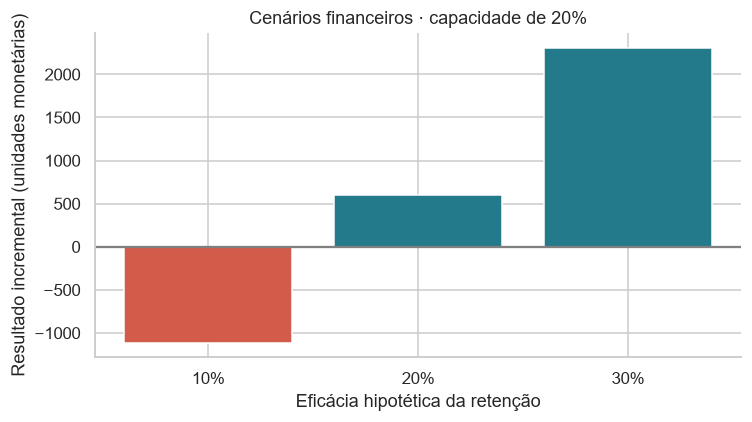

In [19]:
CUSTO_CONTATO=10.0
MESES=3
MARGEM=.40
CAPACIDADE_FINANCEIRA=.20
top_fin=ranking.head(int(np.ceil(len(ranking)*CAPACIDADE_FINANCEIRA)))
custo=len(top_fin)*CUSTO_CONTATO
valor_retivel=top_fin.loc[top_fin.churn_real.eq(1),"MonthlyCharges"].sum()*MESES*MARGEM
eficacia_equilibrio=float(custo/valor_retivel) if valor_retivel>0 else None
financeiro=pd.DataFrame([
    {"eficacia_hipotetica":e,"contatos":len(top_fin),"custo":custo,
     "beneficio_simulado":e*valor_retivel,"resultado_simulado":e*valor_retivel-custo,
     "ROI_simulado":(e*valor_retivel-custo)/custo,
     "eficacia_equilibrio":eficacia_equilibrio}
    for e in [.10,.20,.30]])
display(financeiro)
salvar_tabela(financeiro,"simulacao_financeira")
fig,ax=plt.subplots(figsize=(7,4))
ax.bar([f"{e:.0%}" for e in financeiro.eficacia_hipotetica],financeiro.resultado_simulado,
       color=["#237a8b" if v>=0 else "#d35b4a" for v in financeiro.resultado_simulado])
ax.axhline(0,color="gray");ax.set(xlabel="Eficácia hipotética da retenção",
    ylabel="Resultado incremental (unidades monetárias)",title="Cenários financeiros · capacidade de 20%")
salvar_figura("11_cenarios_financeiros")

In [20]:
acoes={
    "H1":("Testar migração voluntária para plano anual, com benefício cujo custo caiba na margem.",
          "Churn em 90 dias e margem incremental por cliente contatado"),
    "H2":("Testar acompanhamento de onboarding nos primeiros 12 meses, com contato de suporte.",
          "Churn em 90 dias, satisfação e custo por cliente retido"),
    "H3":("Testar diagnóstico técnico e oferta de segurança/suporte nos perfis de fibra identificados.",
          "Churn em 90 dias, resolução de chamados e margem incremental"),
    "H4":("Testar esclarecimento de cobrança e adesão voluntária ao pagamento automático em faturas altas.",
          "Churn em 90 dias, adesão voluntária e margem incremental"),
}
insights=[]
for r in hipoteses.itertuples():
    acao,kpi=acoes[r.hipotese]
    suporte=bool(r.associacao_sentido_previsto)
    insights.append({"hipotese":r.hipotese,
        "evidencia":f"{r.taxa_exposto:.1%} vs {r.taxa_comparacao:.1%}; diferença {r.diferenca_pp:.1f} p.p.; p-Holm {r.p_holm:.3g}",
        "interpretacao":"Associação no sentido previsto" if suporte else "Evidência insuficiente para priorizar por este contraste",
        "acao":acao if suporte else "Investigar melhor o contraste antes de priorizar intervenção.",
        "avaliacao":kpi,"prazo_proposto":"Piloto prospectivo de 90 dias",
        "criterio_proposto":"Redução relativa de churn ≥ 10% vs controle aleatório, com IC da diferença abaixo de zero e margem incremental positiva"})
insights=pd.DataFrame(insights)
display(insights)
salvar_tabela(insights,"insights_acionaveis")
top20=capacidade_tabela.loc[capacidade_tabela.capacidade_planejada.eq(.2)].iloc[0]
final=metricas(y_test,p_test,LIMIAR)
tn,fp,fn,tp=cm.ravel()
resumo=f'''# Síntese dos resultados

Base: {len(raw):,} clientes; prevalência global de churn {y.mean():.2%}.
Treino {len(X_train):,}, validação {len(X_val):,}, teste {len(X_test):,}.

Selecionado em CV por AP: **{nome_vencedor}**, com calibração sigmoid.
Limiar F2 fixado na validação: **{LIMIAR:.4f}**.
No teste: ROC-AUC **{final['ROC_AUC']:.3f}**, AP **{final['AP']:.3f}**,
precisão **{final['precisao']:.1%}**, revocação **{final['revocacao']:.1%}**,
F1 **{final['F1']:.3f}**, F2 **{final['F2']:.3f}**.
Foram identificados {tp} churns, {fn} não foram sinalizados e houve {fp} falsos positivos.
O limiar sinalizou {final['fracao_contatada']:.1%} dos clientes do teste.

Com capacidade pré-fixada de 20%: {int(top20.contatos)} contatos,
{top20.captura:.1%} dos churns alcançados, precisão {top20.precisao_top:.1%}
e lift {top20.lift:.2f} em relação ao contato aleatório.
Capturar churns retrospectivos não significa evitá-los.

Recomendação: avaliar um piloto prospectivo com grupo controle, capacidade e
premissas financeiras aprovadas pela área de negócio. As quatro ações estão em
`tabelas/insights_acionaveis.csv`; só as que têm evidência favorável devem ser
priorizadas a partir destes contrastes. A meta de 10% é proposta para o piloto,
não ganho observado. Dimensionar a amostra e ajustar múltiplas comparações antes
do experimento. Validar disponibilidade das variáveis antes do cancelamento.
'''
display(Markdown(resumo))
(OUT/"resumo_resultados.md").write_text(resumo,encoding="utf-8")

,hipotese,evidencia,interpretacao,acao,avaliacao,prazo_proposto,criterio_proposto
0,H1,43.1% vs 6.3%; diferença 36.8 p.p.; p-Holm 1.7...,Associação no sentido previsto,"Testar migração voluntária para plano anual, c...",Churn em 90 dias e margem incremental por clie...,Piloto prospectivo de 90 dias,Redução relativa de churn ≥ 10% vs controle al...
1,H2,47.3% vs 17.1%; diferença 30.1 p.p.; p-Holm 2....,Associação no sentido previsto,Testar acompanhamento de onboarding nos primei...,"Churn em 90 dias, satisfação e custo por clien...",Piloto prospectivo de 90 dias,Redução relativa de churn ≥ 10% vs controle al...
2,H3,45.9% vs 14.0%; diferença 31.9 p.p.; p-Holm 4....,Associação no sentido previsto,Testar diagnóstico técnico e oferta de seguran...,"Churn em 90 dias, resolução de chamados e marg...",Piloto prospectivo de 90 dias,Redução relativa de churn ≥ 10% vs controle al...
3,H4,47.1% vs 21.7%; diferença 25.4 p.p.; p-Holm 2....,Associação no sentido previsto,Testar esclarecimento de cobrança e adesão vol...,"Churn em 90 dias, adesão voluntária e margem i...",Piloto prospectivo de 90 dias,Redução relativa de churn ≥ 10% vs controle al...


# Síntese dos resultados

Base: 7,043 clientes; prevalência global de churn 26.54%.
Treino 4,225, validação 1,409, teste 1,409.

Selecionado em CV por AP: **Random Forest**, com calibração sigmoid.
Limiar F2 fixado na validação: **0.1003**.
No teste: ROC-AUC **0.843**, AP **0.654**,
precisão **41.7%**, revocação **93.6%**,
F1 **0.577**, F2 **0.749**.
Foram identificados 350 churns, 24 não foram sinalizados e houve 489 falsos positivos.
O limiar sinalizou 59.5% dos clientes do teste.

Com capacidade pré-fixada de 20%: 282 contatos,
49.2% dos churns alcançados, precisão 65.2%
e lift 2.46 em relação ao contato aleatório.
Capturar churns retrospectivos não significa evitá-los.

Recomendação: avaliar um piloto prospectivo com grupo controle, capacidade e
premissas financeiras aprovadas pela área de negócio. As quatro ações estão em
`tabelas/insights_acionaveis.csv`; só as que têm evidência favorável devem ser
priorizadas a partir destes contrastes. A meta de 10% é proposta para o piloto,
não ganho observado. Dimensionar a amostra e ajustar múltiplas comparações antes
do experimento. Validar disponibilidade das variáveis antes do cancelamento.


1156

## 11. Exportação e exemplo de reutilização

O arquivo joblib contém o pipeline calibrado, que recebe os **19 preditores brutos**,
e o limiar fixado. Não exige preparar dummies manualmente. `telco_pipeline.py`
deve acompanhar o modelo. Não carregar artefatos joblib de terceiros.
O exemplo usa um cliente do teste para demonstrar a API, sem refazer treinamento.
Não se trata de contato comercial com clientes ativos.

In [21]:
metadados={
    "gerado_em_utc":datetime.now(timezone.utc).isoformat(),"seed":SEED,
    "csv":CSV.name,"sha256_csv":HASH_CSV,"python":platform.python_version(),
    "versoes":versoes,"modelo":nome_vencedor,
    "parametros":buscas[nome_vencedor].best_params_,"limiar":LIMIAR,
    "metrica_selecao":"average_precision","metrica_limiar":"F2 na validação",
    "calibracao":"sigmoid, 3 folds no treino; ensemble=True",
    "particoes":{"treino":len(X_train),"validacao":len(X_val),"teste":len(X_test)},
    "preditores":PREDITORES,"q75_fatura_treino":q75_fatura,
    "metricas_teste":{k:float(v) for k,v in final.items()},
    "financeiro":{"custo_contato":CUSTO_CONTATO,"meses":MESES,"margem":MARGEM,
                   "capacidade":CAPACIDADE_FINANCEIRA,"eficacia_equilibrio":eficacia_equilibrio},
    "limitacoes":["Base observacional amostral, sem validação temporal",
        "Horizonte futuro e disponibilidade pré-cancelamento não comprovados",
        "Associações não causais e retorno financeiro hipotético",
        "Modelo ajustado apenas no treino; não foi retreinado após avaliação"],
}
(OUT/"metadados.json").write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding="utf-8")
joblib.dump({"pipeline":modelo,"limiar":LIMIAR,"metadados":metadados},OUT/"modelo_churn.joblib",compress=3)
artefato=joblib.load(OUT/"modelo_churn.joblib")
exemplo=X_test.iloc[[0]].copy()
prob=float(artefato["pipeline"].predict_proba(exemplo)[0,1])
assert np.isclose(prob,p_test[0])
display(pd.DataFrame([{"probabilidade_estimada":prob,"limiar":artefato["limiar"],
    "sinalizar_no_estudo":prob>=artefato["limiar"]}]))
exemplo.to_csv(OUT/"exemplo_entrada.csv",index=False,encoding="utf-8-sig")
assert hashlib.sha256(CSV.read_bytes()).hexdigest()==HASH_CSV, "A base original foi alterada."
assert all(np.isfinite(v) for v in final.values())
print("Modelo, metadados, exemplo, tabelas e figuras exportados para",OUT)

,probabilidade_estimada,limiar,sinalizar_no_estudo
0,0.0570,0.1003,False


Modelo, metadados, exemplo, tabelas e figuras exportados para C:\Users\youxv\Desktop\Projetos\ufal\projeto-cd\outputs


## 12. Discussão crítica e próximos passos

- A base é observacional e amostral. Contrato, preço e suporte podem refletir
  fatores não medidos; mudar um atributo no simulador não mede efeito de uma oferta.
- `tenure` mede permanência observada e pode ser afetado pela saída; há viés de
  sobrevivência. Não estimamos hazard nem curva de sobrevivência com estes dados.
- Valores financeiros e serviços precisam estar disponíveis **antes** do churn
  no uso real. Sem timestamp e janela de previsão, não podemos garantir isso.
- Sexo/gênero e idade aparecem na base. Antes de uso real, avaliar desempenho e
  critérios de atendimento entre grupos, necessidade dessas variáveis e eventuais
  disparidades. Este estudo não realizou uma auditoria completa de equidade.
- Não coletamos custos reais, margem, sucesso de retenção, CAC nem CLV. A
  simulação não demonstra lucro e a meta proposta não é resultado do modelo.
- A amostra de validação foi usada para limiar e interpretação; métricas nela são
  de desenvolvimento. Os ICs de teste são condicionais ao modelo treinado.
- As configurações e o conjunto de atributos foram limitados por escopo. Não há
  comparação de ablação para demonstrar ganho individual das variáveis derivadas.
- Para produção: dados temporais com variáveis anteriores ao evento, avaliação
  temporal, estudo de calibração e equidade, piloto aleatorizado e monitoramento
  de drift, custo e capacidade. Streamlit consta como extensão planejada, não
  implementada neste notebook.

### Uso na entrega da disciplina

| Seção do artigo SBC (até 12 páginas) | Evidência neste notebook |
|---|---|
| Aplicação | Seção 1: problema e decisão |
| Base de dados | Seções 2–3: dicionário, auditoria, tratamentos e partições |
| Descritiva e inferência | Seções 4–5: gráficos e H1–H4 com Holm |
| Métodos, métricas e avaliação | Seções 6–8: CV, calibração, limiar e teste |
| Resultados e discussão | Seções 8–10: métricas, captura, interpretação e ações |
| Conclusão e bibliografia | Síntese gerada, limitações e fontes abaixo |

Para o pitch de 5 minutos: tamanho do problema → três evidências de associação
com ação proposta → ranking e capacidade → piloto e impacto hipotético.
Nos 15 minutos técnicos: demonstrar tratamentos, ausência de vazamento, CV,
calibração, limiar, teste e limitações. O notebook não substitui o PDF final
nem a apresentação exigidos na entrega.

## Referências e rastreabilidade

1. Materiais locais da disciplina: `Projeto (2026-1).pdf` e `Aula_cd_projeto.pdf`.
2. Proposta inicial da equipe: Google Docs indicado na seção 1 e cópia em
   `docs/proposta_inicial.txt` (lida em 15/11/2026).
3. Origem da base declarada na proposta: IBM / Kaggle, link na seção 1;
   arquivo efetivamente usado identificado por SHA-256 em `outputs/metadados.json`.
4. Implementações e versões dos métodos: pacotes locais identificados na primeira
   célula e em `requirements-lock.txt`; protocolo e parâmetros exportados nos metadados.

Não foram atribuídos custos ou efeitos causais a fontes externas. O conteúdo
restrito do Overleaf não integra as evidências consultadas.

## 13. Baixar resultados no Colab

Após a execução, esta célula compacta `outputs/` e `telco_pipeline.py` em
`resultados_churn.zip` e inicia o download. O módulo deve acompanhar o modelo
para sua recarga. O ZIP inclui a base limpa, tabelas, figuras, modelo, metadados e
resumo. Para guardar também este notebook com as saídas, baixe o `.ipynb` pelo
menu do Colab. Os arquivos da máquina virtual são temporários.

Na execução local, as saídas continuam em `outputs/` e esta célula não inicia download.
Referências oficiais: [FAQ do Colab](https://research.google.com/colaboratory/faq.html)
e [API de arquivos](https://github.com/googlecolab/colabtools/blob/main/google/colab/files.py).

In [22]:
if NO_COLAB:
    from zipfile import ZipFile, ZIP_DEFLATED

    if not (OUT / "metadados.json").is_file() or not (OUT / "modelo_churn.joblib").is_file():
        raise RuntimeError("Execute todas as etapas do notebook antes de baixar os resultados.")
    arquivo_zip = ROOT / "resultados_churn.zip"
    with ZipFile(arquivo_zip, "w", compression=ZIP_DEFLATED) as pacote:
        for arquivo in sorted(OUT.rglob("*")):
            if arquivo.is_file():
                pacote.write(arquivo, arcname=arquivo.relative_to(ROOT).as_posix())
        pacote.write(ROOT / "telco_pipeline.py", arcname="telco_pipeline.py")
    print(f"Resultados compactados: {arquivo_zip.name}")
    arquivos_colab.download(str(arquivo_zip))
else:
    print("Resultados locais disponíveis em", OUT)

Resultados locais disponíveis em C:\Users\youxv\Desktop\Projetos\ufal\projeto-cd\outputs
